In [ ]:
# Общие импорты и локальные данные JERICHON
import os, sys
from pathlib import Path

_HERE = Path(globals().get("__vsc_ipynb_file__", Path.cwd())).expanduser().resolve()
_CANDIDATES = [_HERE, *_HERE.parents, Path.cwd().resolve(), *Path.cwd().resolve().parents]
PROJECT_ROOT = next((p for p in dict.fromkeys(_CANDIDATES)
                     if (p / "src" / "data" / "load_data.py").is_file()
                     and (p / "research").is_dir()), None)
if PROJECT_ROOT is None and os.environ.get("JERICHON_PROJECT_ROOT"):
    PROJECT_ROOT = Path(os.environ["JERICHON_PROJECT_ROOT"]).expanduser().resolve()
if PROJECT_ROOT is None or not (PROJECT_ROOT / "src" / "data" / "load_data.py").is_file():
    raise FileNotFoundError("Не найден корень JERICHON с src/data/load_data.py")
sys.path[:0] = [str(PROJECT_ROOT), str(PROJECT_ROOT / "data")]
from src.data.load_data import *
ROOT = PROJECT_ROOT


# JERICHON AFML_07 — Режимы по целевому поведению, а не по похожести признаков

**Гипотеза:** рынок может переключаться между повторяющимися типами будущего поведения — например, направленное движение, возврат/малое движение, высокая амплитуда с неопределённым направлением. Эти режимы определяются по *исходам*, а не по расстояниям между 474 входными признаками.

**Ключевое разграничение:**
- Режим — описательная метка будущего поведения (target archetype), построенная по будущим исходам.
- Признаки в момент `t` используются только для проверки, можно ли заранее предсказывать такой режим.
- Режим на графике цены — ретроспективная разметка, потому что его определение использует будущие исходы. Сам по себе этот график не является торговым сигналом.

Ноутбук локальный: API не вызывается. Для работы нужны репозиторий JERICHON, AlgoPack parquet и зависимости проекта.

## 1. Настройки исследования

Сначала запускаем один тикер и фиксированную сборку датасета. Важно: здесь **не оптимизируем** `dollar_threshold` / CUSUM / TP-SL — это отдельная задача AFML_06. Здесь проверяем гипотезу о структуре целевого поведения при фиксированных параметрах.

In [1]:
from pathlib import Path
import os, sys, json, math, hashlib, warnings, inspect
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, RobustScaler
from sklearn.cluster import KMeans
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier, HistGradientBoostingClassifier
from sklearn.metrics import (f1_score, balanced_accuracy_score, accuracy_score,
                             confusion_matrix, classification_report, ConfusionMatrixDisplay)
from sklearn.decomposition import PCA
import mplcyberpunk
plt.style.use('cyberpunk')

TICKER = "GAZP"
DOLLAR_THRESHOLD = 10_000_000
CUSUM_THRESHOLD = 0.001
PT_MULT = 1.0
SL_MULT = 1.0
VERTICAL_HORIZON = 50
TARGET_WINDOW = 55
OUTCOME_HORIZONS = (3, 5, 10, 20)
N_BEHAVIOR_REGIMES = 4
SEED = 63
EXPECTED_FEATURES = 474
SCALER_NAME = "robust"  # "robust" либо "standard"
PROJECT_ROOT = None  # При необходимости задай Path(r"D:\путь\к\JERICHON")
CACHE_VERSION = "target_behavior_v1"
CACHE_DIR_NAME = "afml07_cache"
OUT_DIR_NAME = "research/afml/afml_07_target_behavior_regimes/results"

plt.rcParams["figure.figsize"] = (12, 5)
plt.rcParams["axes.grid"] = True
print("Тикер:", TICKER, "| Dollar threshold:", DOLLAR_THRESHOLD,
      "| CUSUM:", CUSUM_THRESHOLD, "| горизонты:", OUTCOME_HORIZONS)

Тикер: GAZP | Dollar threshold: 10000000 | CUSUM: 0.001 | горизонты: (3, 5, 10, 20)


## 2. Поиск проекта и загрузка локального AlgoPack

Подгружаем те же 474 признака через канонический `jerichon_feature_pipeline.py`, что и в предыдущих AFML-экспериментах. Источники Super Candles присоединяются штатным методом доступности; столбцы `__available_at` / `__event_ts` не попадут в модель.

In [2]:

ROOT = PROJECT_ROOT
DATA_ROOT = ROOT / "data" if (ROOT / "data").exists() else ROOT
if str(ROOT) not in sys.path: sys.path.insert(0, str(ROOT))
from src.data.builders import jerichon_feature_pipeline as jfp
from src.data.labeling.cusum import cusum_filter
from src.data.labeling.triple_barrier import triple_barrier_labeling

CACHE_DIR = DATA_ROOT / CACHE_DIR_NAME
OUT_DIR = ROOT / OUT_DIR_NAME
CACHE_DIR.mkdir(parents=True, exist_ok=True)
OUT_DIR.mkdir(parents=True, exist_ok=True)
print("Project root:", ROOT)
print("History:", HISTORY_ROOT)
print("Pipeline:", inspect.getfile(jfp))

data, SAVED_DATES = load_local_history(TICKER, HISTORY_ROOT)

def normalize_time_col(frame, candidates=("bar_ts", "close_time", "ts")):
    frame = frame.copy()
    if "bar_ts" not in frame.columns:
        found = next((x for x in candidates if x in frame.columns), None)
        if found is None and isinstance(frame.index, pd.DatetimeIndex):
            frame = frame.reset_index().rename(columns={frame.index.name or "index": "bar_ts"})
        elif found is not None:
            frame = frame.rename(columns={found: "bar_ts"})
    if "bar_ts" not in frame.columns:
        raise RuntimeError(f"Нет временной колонки; columns={list(frame.columns)[:20]}")
    frame["bar_ts"] = pd.to_datetime(frame["bar_ts"], errors="coerce", utc=True)
    return frame.dropna(subset=["bar_ts"]).sort_values("bar_ts").drop_duplicates("bar_ts", keep="last").reset_index(drop=True)

def resolve_feature_frame(source, frames):
    if source in frames:
        return frames[source]
    matches = [k for k in frames if source.lower() in str(k).lower()]
    if len(matches) == 1:
        return frames[matches[0]]
    raise RuntimeError(f"Не удалось сопоставить {source}; доступны: {list(frames)}")

Project root: C:\Users\Сергей Кравцов\Desktop\Morgan Co\JERICHON
History: C:\Users\Сергей Кравцов\Desktop\Morgan Co\JERICHON\data\for_ml\storage\history
Pipeline: C:\Users\Сергей Кравцов\Desktop\Morgan Co\JERICHON\data\for_ml\builders\jerichon_feature_pipeline.py
Дат: 21 | 2026-09-24 → 2026-10-29


,источник,строк
0,candles,18873
1,trades,1878016
2,orderbook,420
3,tradestats,3792
4,obstats,3687
5,orderstats,3813


## 3. Построение и кэширование 474 признаков + Dollar Bars

Кэш ключуется тикером, порогом и версией. Если сборка уже была выполнена, повторный запуск не пересчитывает признаки.

In [3]:
def cache_key(payload):
    raw = json.dumps(payload, sort_keys=True, default=str).encode("utf-8")
    return hashlib.sha256(raw).hexdigest()[:20]

def build_features_and_bars():
    key = cache_key({"version": CACHE_VERSION, "ticker": TICKER, "dollar_threshold": DOLLAR_THRESHOLD})
    fp = CACHE_DIR / f"{TICKER}_{key}_features.parquet"
    bp = CACHE_DIR / f"{TICKER}_{key}_bars.parquet"
    if fp.exists() and bp.exists():
        ft, bars = normalize_time_col(pd.read_parquet(fp)), normalize_time_col(pd.read_parquet(bp))
        print(f"CACHE HIT: bars={len(bars):,}, features={len(ft):,}")
        return ft, bars

    bars = jfp.build_dollar_bars_from_trades(data["trades"], threshold=int(DOLLAR_THRESHOLD))
    if bars is None or bars.empty:
        raise RuntimeError("Dollar Bars пусты")
    bars = normalize_time_col(bars)
    base = jfp._base(bars.copy())
    if isinstance(base, tuple):
        base = base[0]
    if not isinstance(base, pd.DataFrame):
        raise TypeError("jfp._base должен вернуть DataFrame")
    base = normalize_time_col(base)

    bsc = bars.copy()
    if "ts" not in bsc.columns:
        bsc["ts"] = bsc["bar_ts"]
    if "CLOSE" not in bsc.columns:
        if "close" in bsc.columns: bsc["CLOSE"] = bsc["close"]
        else: raise RuntimeError("В Dollar Bars нет close/CLOSE")
    bsc["ts"] = pd.to_datetime(bsc["ts"], errors="coerce", utc=True)
    sc_result = jfp._build_sc_features(data, bsc.dropna(subset=["ts"]).sort_values("ts").reset_index(drop=True))
    feature_frames = sc_result[0] if isinstance(sc_result, tuple) else sc_result
    if not isinstance(feature_frames, dict):
        raise TypeError("_build_sc_features должен вернуть dict")
    for source in ("tradestats", "obstats", "orderstats"):
        jfp._choose_availability(data[source].copy(), source)
    causal = bars.copy()
    for source in ("tradestats", "obstats", "orderstats"):
        attached = jfp._attach_source(causal, resolve_feature_frame(source, feature_frames), data[source], source)
        if isinstance(attached, pd.DataFrame):
            causal = attached

    base_cols = [x for x in base.columns if x != "bar_ts" and pd.api.types.is_numeric_dtype(base[x])]
    if len(base_cols) != 73:
        raise RuntimeError(f"Ожидалось 73 базовых признака, найдено {len(base_cols)}")
    bj = base[["bar_ts"] + base_cols].copy().rename(columns={x: f"base__{x}" for x in base_cols})
    causal = normalize_time_col(causal).merge(bj, on="bar_ts", how="left", validate="one_to_one")
    provenance = [x for x in causal.columns if x.endswith("__event_ts") or x.endswith("__available_at")]
    prefixes = ("tradestats__", "obstats__", "orderstats__")
    sc_cols = [x for x in causal.columns if x.startswith(prefixes) and x not in provenance and pd.api.types.is_numeric_dtype(causal[x])]
    feature_cols = [x for x in causal.columns if x.startswith("base__")] + sc_cols
    if len(feature_cols) != EXPECTED_FEATURES:
        raise RuntimeError(f"Ожидалось {EXPECTED_FEATURES} признаков, найдено {len(feature_cols)}")
    ft = normalize_time_col(causal[["bar_ts"] + feature_cols + provenance])
    bars.to_parquet(bp, index=False); ft.to_parquet(fp, index=False)
    print(f"CACHE BUILD: bars={len(bars):,}, features={len(ft):,}")
    return ft, bars

features, bars = build_features_and_bars()
print("Размеры:", bars.shape, features.shape)

C:\Users\Сергей Кравцов\Desktop\Morgan Co\JERICHON\data\for_ml\builders\jerichon_feature_pipeline.py:77: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  out[f"{c}_z{w}"] = (s - mean) / (std + 1e-12)
C:\Users\Сергей Кравцов\Desktop\Morgan Co\JERICHON\data\for_ml\builders\jerichon_feature_pipeline.py:78: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  out[f"{c}_ma{w}"] = mean
C:\Users\Сергей Кравцов\Desktop\Morgan Co\JERICHON\data\for_ml\builders\jerichon_feature_pipeline.py:71: PerformanceWarning: DataFrame is highly fragmented.  Thi

CACHE BUILD: bars=13,805, features=13,805
Размеры: (13805, 10) (13805, 481)


## 4. Раздел исследования: статистики целевого поведения

**Этот раздел идёт до поиска режимов.** Для каждого события рассчитываем только как *целевые описатели*:
- будущую лог-доходность на горизонтах 3/5/10/20 баров;
- абсолютную доходность и диапазон будущего движения;
- максимальное благоприятное/неблагоприятное движение (MFE/MAE — максимальная благоприятная/неблагоприятная экскурсия);
- результат Triple Barrier и время до завершения события.

Графики ниже нужны, чтобы глазами увидеть асимметрию, хвосты и взаимосвязь будущих исходов до кластеризации. Эти значения **не являются входными признаками модели**.

In [4]:
bars = normalize_time_col(bars)
bars = bars.set_index("bar_ts", drop=False).sort_index()
close_col = "close" if "close" in bars.columns else "CLOSE"
high_col = "high" if "high" in bars.columns else "HIGH"
low_col = "low" if "low" in bars.columns else "LOW"
open_col = "open" if "open" in bars.columns else "OPEN"
for col in (close_col, high_col, low_col):
    if col not in bars.columns:
        raise RuntimeError(f"Не найдена OHLC колонка {col}; columns={bars.columns.tolist()[:30]}")
close = pd.to_numeric(bars[close_col], errors="coerce")
high = pd.to_numeric(bars[high_col], errors="coerce")
low = pd.to_numeric(bars[low_col], errors="coerce")
events = pd.DatetimeIndex(cusum_filter(close, threshold=float(CUSUM_THRESHOLD)))
events = events[events.isin(bars.index)].drop_duplicates().sort_values()
if len(events) < 200:
    raise RuntimeError(f"Слишком мало CUSUM событий: {len(events)}")
ev = pd.DataFrame(index=events)
pos = bars.index.get_indexer(events)
for h in OUTCOME_HORIZONS:
    future_close = close.reindex(bars.index).shift(-h).reindex(events).to_numpy()
    start_close = close.reindex(events).to_numpy()
    ev[f"fwd_logret_{h}"] = np.log(future_close / start_close)
    future_hi = np.vstack([high.shift(-j).reindex(events).to_numpy() for j in range(1, h+1)]).T
    future_lo = np.vstack([low.shift(-j).reindex(events).to_numpy() for j in range(1, h+1)]).T
    ev[f"mfe_{h}"] = np.nanmax(future_hi / start_close[:, None] - 1.0, axis=1)
    ev[f"mae_{h}"] = np.nanmin(future_lo / start_close[:, None] - 1.0, axis=1)
    ev[f"future_range_{h}"] = (np.nanmax(future_hi, axis=1) - np.nanmin(future_lo, axis=1)) / start_close
ev = ev.replace([np.inf, -np.inf], np.nan).dropna(subset=[f"fwd_logret_{OUTCOME_HORIZONS[-1]}"])
display(ev.describe(percentiles=[.01,.05,.25,.5,.75,.95,.99]).T.round(5))
print("Событий с полными будущими окнами:", len(ev))

,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,max
fwd_logret_3,3945.0,0.00001,0.00167,-0.00634,-0.00319,-0.00208,-0.00090,0.00000,0.00082,0.00218,0.00318,0.04613
mfe_3,3945.0,0.00099,0.00138,-0.00266,-0.00010,0.00000,0.00034,0.00077,0.00140,0.00258,0.00358,0.05080
mae_3,3945.0,-0.00094,0.00084,-0.00714,-0.00362,-0.00253,-0.00137,-0.00076,-0.00031,0.00000,0.00010,0.00119
future_range_3,3945.0,0.00193,0.00136,0.00009,0.00058,0.00086,0.00135,0.00176,0.00229,0.00334,0.00472,0.05162
fwd_logret_5,3945.0,-0.00001,0.00194,-0.00746,-0.00388,-0.00271,-0.00114,0.00000,0.00104,0.00271,0.00423,0.04025
mfe_5,3945.0,0.00126,0.00153,-0.00266,-0.00010,0.00000,0.00044,0.00100,0.00175,0.00325,0.00464,0.05080
mae_5,3945.0,-0.00123,0.00104,-0.00793,-0.00447,-0.00319,-0.00177,-0.00100,-0.00044,0.00000,0.00010,0.00104
future_range_5,3945.0,0.00249,0.00148,0.00035,0.00082,0.00117,0.00178,0.00227,0.00295,0.00427,0.00575,0.05162
fwd_logret_10,3945.0,0.00004,0.00280,-0.00931,-0.00503,-0.00361,-0.00155,-0.00009,0.00144,0.00367,0.00584,0.06711
mfe_10,3945.0,0.00181,0.00234,-0.00225,-0.00009,0.00009,0.00063,0.00144,0.00251,0.00452,0.00695,0.07085


Событий с полными будущими окнами: 3945


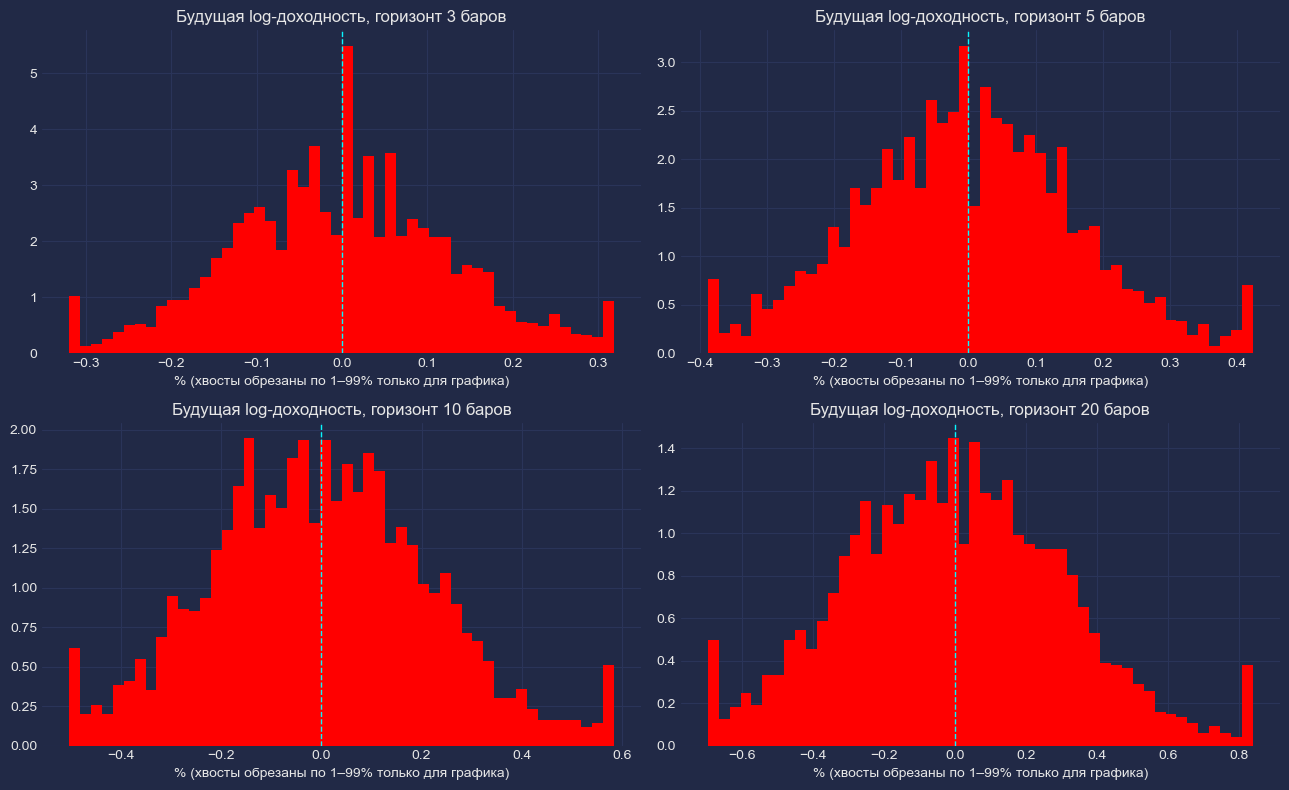

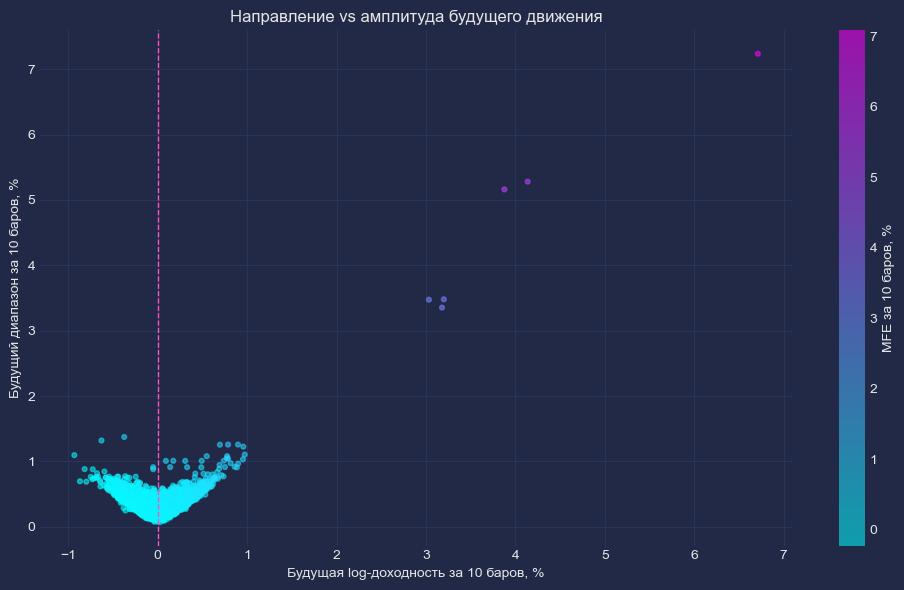

In [5]:
# График 1: распределения будущих доходностей — показывает асимметрию и тяжёлые хвосты.
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
for ax, h in zip(axes.ravel(), OUTCOME_HORIZONS):
    s = ev[f"fwd_logret_{h}"].dropna() * 100
    lo, hi = s.quantile([0.01, 0.99])
    ax.hist(s.clip(lo, hi), bins=50, density=True, color='C4')
    ax.axvline(0, linestyle="--", linewidth=1)
    ax.set_title(f"Будущая log-доходность, горизонт {h} баров")
    ax.set_xlabel("% (хвосты обрезаны по 1–99% только для графика)")
plt.tight_layout()
plt.show()

# График 2: соотношение направления и амплитуды будущего движения.
fig, ax = plt.subplots(figsize=(10, 6))
sample = ev.sample(min(5000, len(ev)), random_state=SEED)
sc = ax.scatter(sample["fwd_logret_10"]*100, sample["future_range_10"]*100,
                c=sample["mfe_10"]*100, s=12, alpha=0.55)
ax.axvline(0, color="C1", linewidth=1, linestyle="--")
ax.set_xlabel("Будущая log-доходность за 10 баров, %")
ax.set_ylabel("Будущий диапазон за 10 баров, %")
ax.set_title("Направление vs амплитуда будущего движения")
fig.colorbar(sc, ax=ax, label="MFE за 10 баров, %")
plt.tight_layout()
plt.show()

## 5. Добавляем Triple Barrier исходы и формируем поведенческие типы

Режимы задаются по вектору *будущего поведения*, а не по исходным 474 признакам. В кластеризацию целевого поведения входят будущие доходности, диапазоны и MFE/MAE. KMeans здесь используется как компактный способ найти несколько архетипов поведения; это не утверждение, что рынку обязательно соответствуют ровно четыре истинных режима.

Для защиты от утечки: scaler и KMeans обучаются только на ранней части временной шкалы. Для последующих наблюдений применяется уже обученный кластеризатор к их **будущим исходам** — это формирует целевые метки для последующего теста предсказуемости, а не торговые сигналы.

In [6]:
# Triple Barrier outcome: сохраняем label и t1. Время переводим в UTC и
# считаем длительность через позиции баров, а не через reindex по tz-naive/tz-aware индексам.
label_bars = bars[[open_col, high_col, low_col, close_col]].copy()
label_bars.columns = ["OPEN", "HIGH", "LOW", "CLOSE"]

# Triple Barrier ожидает временной DatetimeIndex.
label_bars.index = pd.to_datetime(label_bars.index, errors="coerce", utc=True)
label_bars = label_bars.loc[~label_bars.index.isna()].sort_index()
label_bars = label_bars[~label_bars.index.duplicated(keep="last")]

events_utc = pd.DatetimeIndex(pd.to_datetime(events, errors="coerce", utc=True))
events_utc = events_utc[~events_utc.isna()]
tb = triple_barrier_labeling(
    bars=label_bars,
    events=events_utc,
    pt_sl=(float(PT_MULT), float(SL_MULT)),
    vertical_barrier=int(VERTICAL_HORIZON),
    target_window=int(TARGET_WINDOW),
    target_method="ewm",
)
if tb is None or tb.empty or not {"label", "t1"}.issubset(tb.columns):
    raise RuntimeError("Triple Barrier не вернул ожидаемые label/t1")

tb = tb.copy()
tb.index = pd.DatetimeIndex(pd.to_datetime(tb.index, errors="coerce", utc=True))
tb = tb.loc[~tb.index.isna()].sort_index()
tb = tb[~tb.index.duplicated(keep="last")]
tb["t1"] = pd.to_datetime(tb["t1"], errors="coerce", utc=True)

# ev может иметь tz-naive индекс, а bars/tb — tz-aware. Нормализуем обе стороны.
ev.index = pd.DatetimeIndex(pd.to_datetime(ev.index, errors="coerce", utc=True))
ev = ev.loc[~ev.index.isna()].sort_index()
ev = ev[~ev.index.duplicated(keep="last")]
ev = ev.join(tb[["label", "t1"]], how="left")

# Длительность: позиция ближайшего бара с timestamp >= t1 минус позиция бара события.
# Для t1, попавшего точно на бар, это точная позиционная разница.
bar_index = pd.DatetimeIndex(label_bars.index)
event_index = pd.DatetimeIndex(ev.index)
event_pos = bar_index.get_indexer(event_index)
end_ns = pd.DatetimeIndex(ev["t1"]).asi8
bar_ns = bar_index.asi8
end_pos = np.full(len(ev), np.nan, dtype=float)
valid_end = ~pd.isna(ev["t1"]).to_numpy()
end_pos[valid_end] = np.searchsorted(bar_ns, end_ns[valid_end], side="left")
# Не допускаем фиктивную длительность для событий вне диапазона баров.
valid_event = event_pos >= 0
dur = np.full(len(ev), np.nan, dtype=float)
ok = valid_event & valid_end & (end_pos < len(bar_index))
dur[ok] = end_pos[ok] - event_pos[ok]
ev["duration_bars"] = dur
ev = ev.replace([np.inf, -np.inf], np.nan)

print("TB labels matched:", int(ev["label"].notna().sum()), "/", len(ev))
print("t1 missing:", int(ev["t1"].isna().sum()))
print("duration_bars missing:", int(ev["duration_bars"].isna().sum()))
if ev["label"].notna().sum() == 0:
    raise RuntimeError("Ни один CUSUM event не сопоставился с Triple Barrier. Проверьте timezone/index contract.")


TB labels matched: 3945 / 3945
t1 missing: 0
duration_bars missing: 0


In [7]:
# Outcome vector: robust-scale по TRAIN, затем KMeans только на TRAIN outcome vectors.
outcome_cols = [f"fwd_logret_{h}" for h in OUTCOME_HORIZONS]
outcome_cols += [f"future_range_{h}" for h in (5, 10, 20) if f"future_range_{h}" in ev.columns]
outcome_cols += [f"mfe_{h}" for h in (5, 10, 20) if f"mfe_{h}" in ev.columns]
outcome_cols += [f"mae_{h}" for h in (5, 10, 20) if f"mae_{h}" in ev.columns]
if "label" in ev:
    ev["tb_label_numeric"] = pd.to_numeric(ev["label"], errors="coerce")
    # label как описатель исхода; оставляем в целевом векторе, а не в признаках модели.
    outcome_cols += ["tb_label_numeric"]
outcome = ev[outcome_cols].replace([np.inf, -np.inf], np.nan)
# Удаляем неполные наблюдения, включая хвост без будущего окна.
valid = outcome.notna().all(axis=1)
ev = ev.loc[valid].copy()
outcome = outcome.loc[valid].copy()
split = int(len(ev) * 0.60)
if split < 100 or len(ev)-split < 50:
    raise RuntimeError("Недостаточно событий для временного train/test")
train_idx = ev.index[:split]
outcome_scaler = RobustScaler()
Z_train = outcome_scaler.fit_transform(outcome.loc[train_idx])
Z_all = outcome_scaler.transform(outcome)
kmeans = KMeans(n_clusters=N_BEHAVIOR_REGIMES, random_state=SEED, n_init=20)
kmeans.fit(Z_train)
ev["behavior_regime"] = kmeans.predict(Z_all).astype(int)
ev["split"] = np.where(np.arange(len(ev)) < split, "train", "test")
print("Распределение целевых режимов:")
display(ev.groupby(["split", "behavior_regime"]).size().unstack(fill_value=0))

C:\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] Не удается найти указанный файл
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "C:\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "C:\anaconda3\Lib\subprocess.py", line 548, in run
    with Popen(*popenargs, **kwargs) as process:
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\anaconda3\Lib\subprocess.py", line 1026, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "C:\anaconda3\Lib\subprocess.py", line 1538, in _execute_child
    hp, ht, pid, tid = _winapi.CreateProcess(executable, args,
                       ^^^^^^^^^^^^^^^^^^^^^^^^

Распределение целевых режимов:


behavior_regime,0,1,2,3
split,,,,
test,354,118,1103,3
train,788,348,1230,1


In [8]:
# Сводка интерпретируемости режимов в исходных единицах.
regime_summary = ev.groupby("behavior_regime").agg(
    n=("behavior_regime", "size"),
    доля=("behavior_regime", lambda x: len(x)/len(ev)),
    tb_up=("label", lambda x: np.mean(pd.to_numeric(x, errors="coerce") == 1)),
    tb_down=("label", lambda x: np.mean(pd.to_numeric(x, errors="coerce") == -1)),
    tb_time=("label", lambda x: np.mean(pd.to_numeric(x, errors="coerce") == 0)),
    средняя_доходность_10=("fwd_logret_10", "mean"),
    медианная_доходность_10=("fwd_logret_10", "median"),
    средний_диапазон_10=("future_range_10", "mean"),
    средний_MFE_10=("mfe_10", "mean"),
    средний_MAE_10=("mae_10", "mean"),
    средняя_длительность=("duration_bars", "mean")
).sort_values("средняя_доходность_10")
display(regime_summary.round(5))
regime_summary.to_csv(OUT_DIR / f"{TICKER}_behavior_regime_summary.csv", encoding="utf-8-sig")

,n,доля,tb_up,tb_down,tb_time,средняя_доходность_10,медианная_доходность_10,средний_диапазон_10,средний_MFE_10,средний_MAE_10,средняя_длительность
behavior_regime,,,,,,,,,,,
0,1142,0.28948,0.16025,0.83538,0.00438,-0.00220,-0.00224,0.00406,0.00063,-0.00342,49.99387
2,2333,0.59138,0.59108,0.40334,0.00557,0.00040,0.00040,0.00284,0.00172,-0.00112,49.96871
1,466,0.11812,0.80258,0.18884,0.00858,0.00331,0.00320,0.00534,0.00472,-0.00063,50.00000
3,4,0.00101,0.50000,0.50000,0.00000,0.04242,0.03539,0.04808,0.04741,-0.00068,50.00000


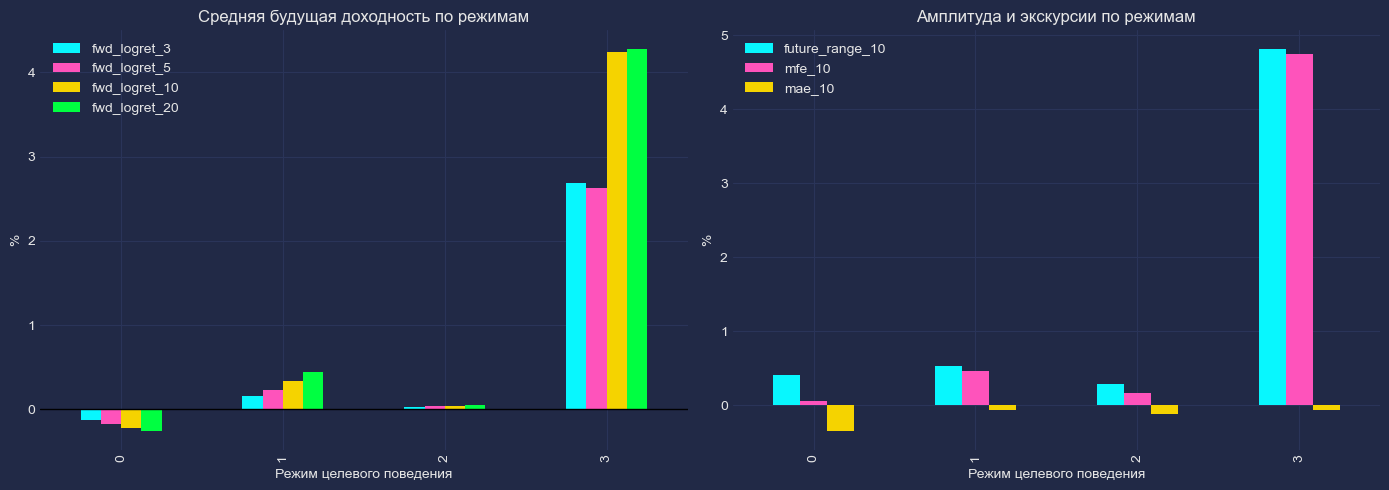

In [9]:
# График 3: профили целевого поведения — помогает понять, чем режимы отличаются.
profile_cols = ["fwd_logret_3", "fwd_logret_5", "fwd_logret_10", "fwd_logret_20",
                "future_range_10", "mfe_10", "mae_10"]
profile = ev.groupby("behavior_regime")[profile_cols].mean()
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
profile[[c for c in profile.columns if c.startswith("fwd_logret")]].mul(100).plot(kind="bar", ax=axes[0])
axes[0].axhline(0, color="black", linewidth=1)
axes[0].set_title("Средняя будущая доходность по режимам")
axes[0].set_ylabel("%")
axes[0].set_xlabel("Режим целевого поведения")
profile[["future_range_10", "mfe_10", "mae_10"]].mul(100).plot(kind="bar", ax=axes[1])
axes[1].set_title("Амплитуда и экскурсии по режимам")
axes[1].set_ylabel("%")
axes[1].set_xlabel("Режим целевого поведения")
plt.tight_layout()
plt.show()

## 6. Полная временная карта режимов на графике цены

Это главный визуальный результат: цена закрытия, окрашенная по ретроспективному режиму будущего поведения. Цвета — категории, а не рекомендации покупать/продавать. Смысл графика — проверить, появляются ли длинные последовательности/эпизоды одного поведения или режимы перемешаны почти случайно.

**Важно:** окраска протягивается между редкими CUSUM-событиями методом forward-fill только для удобства просмотра. Это не означает, что режим был известен в течение всего интервала: он ретроспективно присвоен по будущему исходу события.


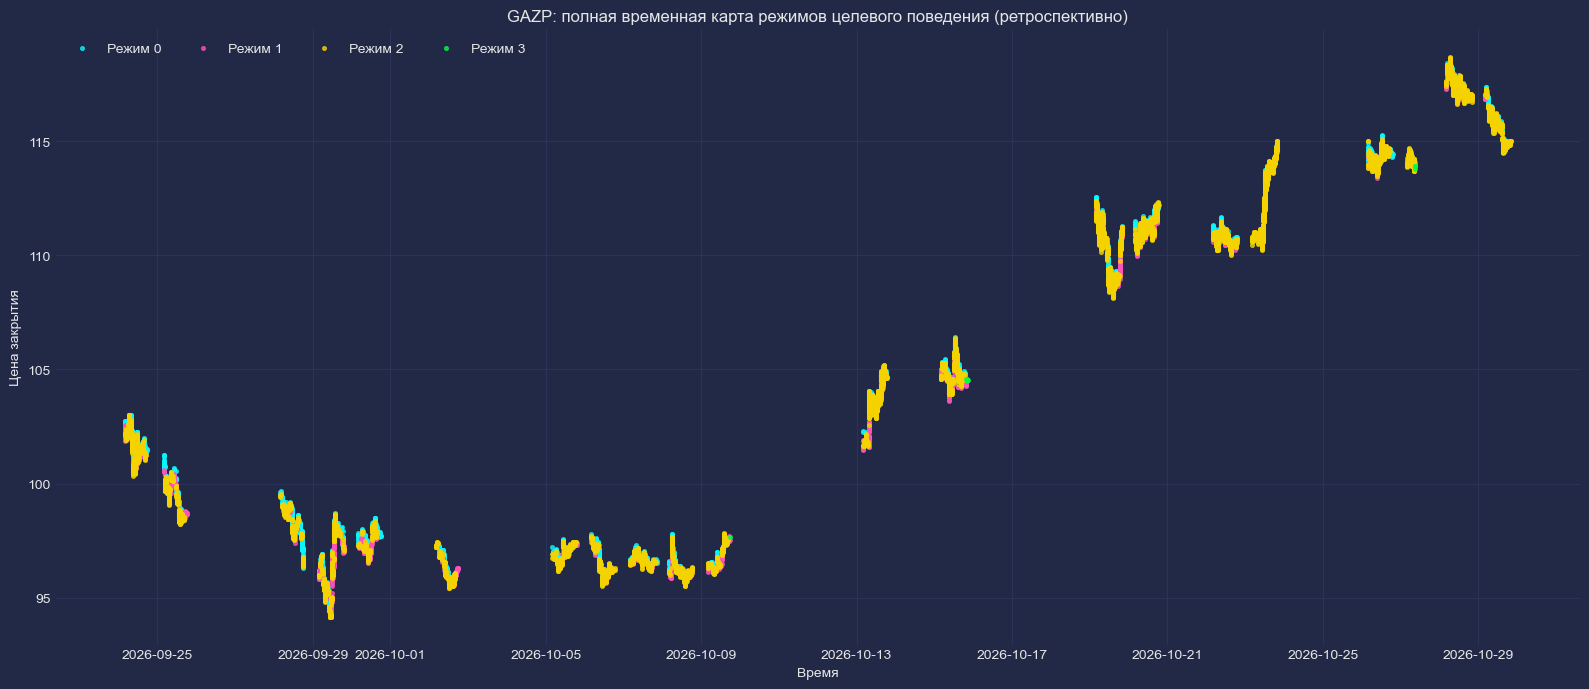

,count,mean,std,min,25%,50%,75%,max
regime,,,,,,,,
0,584.0,5.04,4.72,1.0,2.0,3.0,6.0,35.0
1,246.0,4.35,4.22,1.0,2.0,3.0,5.0,23.0
2,715.0,13.68,17.61,1.0,3.0,8.0,16.0,164.0
3,3.0,4.33,4.16,1.0,2.0,3.0,6.0,9.0


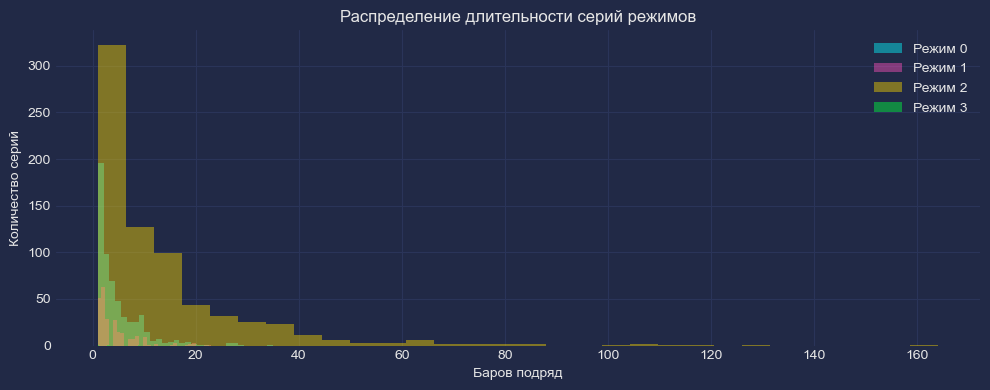

In [10]:
plot_df = bars[[close_col]].rename(columns={close_col: "close"}).copy()
plot_df.index = pd.DatetimeIndex(pd.to_datetime(plot_df.index, errors="coerce", utc=True))
plot_df = plot_df.loc[~plot_df.index.isna()].sort_index()
plot_df = plot_df[~plot_df.index.duplicated(keep="last")]
plot_df["event_regime"] = ev["behavior_regime"].reindex(plot_df.index)
# Для каждой точки между событиями показываем последний наблюдавшийся event regime только для визуализации.
plot_df["regime_for_display"] = plot_df["event_regime"].ffill()
plot_df = plot_df.dropna(subset=["close", "regime_for_display"])
fig, ax = plt.subplots(figsize=(16, 7))
for reg in sorted(plot_df["regime_for_display"].unique()):
    mask = plot_df["regime_for_display"] == reg
    ax.scatter(plot_df.index[mask], plot_df.loc[mask, "close"], s=7, alpha=0.75, label=f"Режим {int(reg)}")
ax.set_title(f"{TICKER}: полная временная карта режимов целевого поведения (ретроспективно)")
ax.set_xlabel("Время")
ax.set_ylabel("Цена закрытия")
ax.legend(ncol=min(N_BEHAVIOR_REGIMES, 4))
plt.tight_layout()
plt.show()

# Длительность серий режимов — важная статистика: не только сколько режимов, но как долго они сохраняются.
r = plot_df["regime_for_display"].astype(int)
run_id = r.ne(r.shift()).cumsum()
runs = plot_df.assign(regime=r, run_id=run_id).groupby(["run_id", "regime"]).size().rename("bars").reset_index()
display(runs.groupby("regime")["bars"].describe().round(2))
fig, ax = plt.subplots(figsize=(10, 4))
for reg, grp in runs.groupby("regime"):
    ax.hist(grp["bars"], bins=30, alpha=0.45, label=f"Режим {reg}")
ax.set_title("Распределение длительности серий режимов")
ax.set_xlabel("Баров подряд")
ax.set_ylabel("Количество серий")
ax.legend()
plt.tight_layout()
plt.show()

## 7. Проверка предсказуемости режима по доступным в момент события признакам

Если режимы определены по будущим исходам, задача модели — предсказать их по информации, доступной на момент события. Это не круговая проверка: будущие целевые описатели не входят в `X`. Для теста оставляем последние 25% событий; на границе удаляем обучающие события, у которых `t1` пересекает начало теста.

Сравниваем простые ансамбли на одинаковых временных данных. Метрики нужны, но здесь важнее также confusion matrix и устойчивость классов: высокая accuracy может получиться за счёт частого режима.

In [11]:
# X — только каузальные 474 признака, без provenance и без целевых outcome-переменных.
ft = normalize_time_col(features).set_index("bar_ts").sort_index()
feature_cols = [c for c in ft.columns if not c.endswith("__event_ts") and not c.endswith("__available_at")
                and pd.api.types.is_numeric_dtype(ft[c])]
if len(feature_cols) != EXPECTED_FEATURES:
    raise RuntimeError(f"В feature frame {len(feature_cols)} числовых признаков вместо {EXPECTED_FEATURES}")
X = ft[feature_cols].reindex(ev.index).replace([np.inf, -np.inf], np.nan)
y = ev["behavior_regime"].astype(int)
t1 = pd.to_datetime(ev["t1"], errors="coerce", utc=True)
n = len(ev)
train_end = int(n * 0.75)
test_start_ts = ev.index[train_end]
train_mask = np.arange(n) < train_end
test_mask = np.arange(n) >= train_end
# Purge обучающих событий, чья метка завершилась в тестовом интервале или позже.
train_mask &= (t1 < test_start_ts).to_numpy()
tr_idx, te_idx = ev.index[train_mask], ev.index[test_mask]
print("Train:", len(tr_idx), "| test:", len(te_idx), "| test start:", test_start_ts)
if len(tr_idx) < 100 or len(te_idx) < 30:
    raise RuntimeError("Недостаточно наблюдений после временного purge")
imputer = SimpleImputer(strategy="median")
scaler = RobustScaler() if SCALER_NAME == "robust" else StandardScaler()
Xtr = imputer.fit_transform(X.loc[tr_idx])
Xte = imputer.transform(X.loc[te_idx])
Xtr = scaler.fit_transform(Xtr)
Xte = scaler.transform(Xte)

Train: 2945 | test: 987 | test start: 2026-10-20 13:34:27+00:00


In [12]:
models = {
    "RandomForest": RandomForestClassifier(n_estimators=250, max_depth=10, min_samples_leaf=8,
        max_features="sqrt", class_weight="balanced_subsample", random_state=SEED, n_jobs=-1),
    "ExtraTrees": ExtraTreesClassifier(n_estimators=250, max_depth=10, min_samples_leaf=8,
        max_features="sqrt", class_weight="balanced", random_state=SEED, n_jobs=-1),
    "HistGradientBoosting": HistGradientBoostingClassifier(max_iter=150, max_leaf_nodes=15,
        learning_rate=0.08, l2_regularization=1.0, random_state=SEED)
}
results, fitted = [], {}
for name, model in models.items():
    model.fit(Xtr, y.loc[tr_idx])
    pred = model.predict(Xte)
    fitted[name] = model
    results.append({
        "model": name, "accuracy": accuracy_score(y.loc[te_idx], pred),
        "balanced_accuracy": balanced_accuracy_score(y.loc[te_idx], pred),
        "f1_macro": f1_score(y.loc[te_idx], pred, average="macro", zero_division=0),
        "f1_weighted": f1_score(y.loc[te_idx], pred, average="weighted", zero_division=0)
    })
metrics = pd.DataFrame(results).sort_values("f1_macro", ascending=False)
display(metrics.round(4))
metrics.to_csv(OUT_DIR / f"{TICKER}_behavior_regime_model_metrics.csv", index=False, encoding="utf-8-sig")

,model,accuracy,balanced_accuracy,f1_macro,f1_weighted
2,HistGradientBoosting,0.6697,0.2755,0.2750,0.6386
0,RandomForest,0.7325,0.2517,0.2190,0.6289
1,ExtraTrees,0.7356,0.2509,0.2145,0.6257


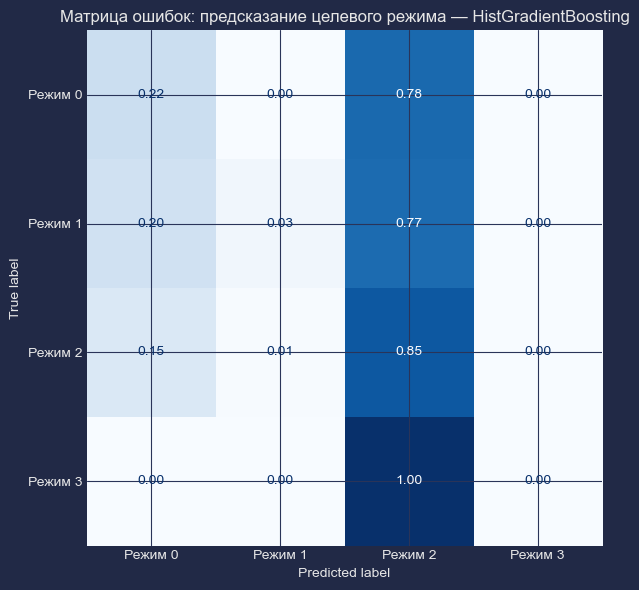

              precision    recall  f1-score   support

           0       0.27      0.22      0.24       198
           1       0.33      0.03      0.06        61
           2       0.75      0.85      0.80       726
           3       0.00      0.00      0.00         2

    accuracy                           0.67       987
   macro avg       0.34      0.28      0.28       987
weighted avg       0.63      0.67      0.64       987



In [13]:
best_name = metrics.iloc[0]["model"]
best_model = fitted[best_name]
pred = best_model.predict(Xte)
labels_sorted = sorted(np.unique(np.r_[y.loc[tr_idx].to_numpy(), y.loc[te_idx].to_numpy()]))
fig, ax = plt.subplots(figsize=(7, 6))
ConfusionMatrixDisplay.from_predictions(y.loc[te_idx], pred, labels=labels_sorted,
    display_labels=[f"Режим {x}" for x in labels_sorted], normalize="true",
    values_format=".2f", cmap="Blues", ax=ax, colorbar=False)
ax.set_title(f"Матрица ошибок: предсказание целевого режима — {best_name}")
plt.tight_layout()
plt.show()
print(classification_report(y.loc[te_idx], pred, zero_division=0))

## 8. Интерпретация и критерии решения

**Поддержка гипотезы** потребует одновременно:
1. режимы имеют разные и интерпретируемые распределения будущих исходов;
2. режимы не сводятся к одному доминирующему классу и не состоят из хаотичных одиночных переключений;
3. по прошлым признакам получается предсказывать режим на хронологическом тесте заметно лучше простого baseline (например, наиболее частого класса);
4. результаты не исчезают при небольшом изменении числа режимов / временного разбиения.

Даже хороший F1 режима **не доказывает торговую прибыльность**. Следующий этап — проверить стабильность на другом периоде/тикере, а затем связать предсказанный режим с каноническим backtest engine. Не использовать ретроспективные цвета режима как торговый сигнал.

Выходы сохраняются в `afml07_target_behavior_outputs`: таблица профилей режимов и метрики моделей. После первого запуска пришли график временной карты и CSV — по ним решим, есть ли содержательная структура.

In [14]:
print("Результаты сохранены в:", OUT_DIR)
print("Файлы:")
for p in sorted(OUT_DIR.glob(f"{TICKER}_behavior_regime_*")):
    print(" -", p.name)

Результаты сохранены в: C:\Users\Сергей Кравцов\Desktop\Morgan Co\JERICHON\afml07_outputs
Файлы:
 - GAZP_behavior_regime_model_metrics.csv
 - GAZP_behavior_regime_summary.csv
